# Feature Importance Done Right: Permutation, SHAP, and Their Limits

**What you'll learn**

- Why "feature importance" is not one thing: impurity/gain, permutation, and SHAP answer
  *different questions* and rank the same features differently — including a pure-noise ID
  feature that impurity-style importance places above genuinely predictive features.
- The Shapley value in a few lines, then TreeSHAP in practice on LightGBM: beeswarm summaries,
  dependence plots with interaction coloring, and a waterfall explanation for one declined
  credit application.
- What correlated features do to every method — permutation manufactures impossible rows, SHAP
  splits credit between near-duplicates — and how grouped/clustered importance repairs the
  summary.
- Why importance is **not** causality, proven with a confounded feature that is highly
  predictive yet has *zero* causal effect: intervening on it does exactly nothing, and we can
  show it because we own the data-generating process.
- PDP and ICE plots, what ICE reveals that PDP averages away, and the extrapolation trap both
  fall into under correlated features.
- How to translate SHAP output for stakeholders: an action memo with honest causal caveats,
  and adverse-action reason codes for a regulated credit decision.

**Why it matters in interviews**

- "Your model says feature X is most important — what should the business do about it?" is a
  classic senior-level trap: the expected answer separates *prediction* from *intervention*.
- "Two importance methods disagree — which is right?" tests whether you know what each method
  actually computes (train vs test, marginal vs conditional, model vs world).
- Explainability questions ("explain SHAP to a PM", "justify a declined loan to a regulator")
  probe whether you can operate where ML meets stakeholders and regulation — the actual senior
  job.
- Model-debugging rounds love the failure modes here: an ID column near the top of an
  importance plot is an overfitting/leakage smell you are expected to catch instantly.

## Setup

Everything runs on one simulated **consumer credit default** dataset with a fully known
data-generating process. Simulation is not a toy choice here — it is the only way to *prove*
statements like "this feature is predictive but not causal" or "this feature carries zero
signal", because we hold the structural equations.
(`../03_causal_inference/01_potential_outcomes_dags.ipynb` develops the formal machinery
behind that distinction.)

In [1]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform
from scipy.special import expit, logit
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import partial_dependence, permutation_importance
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Running example: credit default with known ground truth

One row = one credit-card application; the label is default within 12 months (a subprime-ish
book). The generator has a deliberate causal structure:

- A **latent** variable `h` ("financial health") drives income, delinquencies, credit-history
  length, debt-to-income — and, directly, default risk. `h` is *not* available to the model,
  exactly like real life.
- `premium_card` (holds a premium travel card) is caused by `h` and has **zero** causal effect
  on default. It is a pure confounded proxy — correlated with the outcome only through a
  common cause.
- `dti` and `utilization` are genuinely causal, and utilization's effect is **stronger for
  low-income applicants** (a planted interaction, so SHAP dependence plots have something real
  to find).
- `member_id` is a random unique integer per applicant — **pure noise with maximal
  cardinality**. `noise_flag` is a pure-noise coin flip — identical information content
  (none), minimal cardinality. How differently the methods treat these two is the point of
  section 2.

Causal graph (arrows = the structural equations in the next cell):

```
  h (latent) ──► income, premium_card, dti, num_delinq, credit_history_years
  h ────────────────────────────────────────────► default   (direct effect)
  dti ──► utilization ──► default   (utilization effect stronger when income < $45k)
  dti, num_delinq, recent_inquiries, credit_history_years ──► default
  premium_card ──► (nothing)        member_id, noise_flag ──► (nothing)
```

In [2]:
n = 20_000

h = rng.normal(0, 1, n)                                                     # latent financial health
income = np.clip(58 * np.exp(0.38 * h + rng.normal(0, 0.28, n)), 18, 400)   # $k/year, noisy proxy of h
premium_card = rng.binomial(1, expit(2.6 * h - 0.7))                        # caused by h, NOT causal
dti = np.clip(0.46 - 0.075 * h + rng.normal(0, 0.10, n), 0.02, 1.2)
utilization = np.clip(0.14 + 0.60 * dti + rng.normal(0, 0.12, n), 0.0, 1.0)
credit_history_years = np.clip(rng.gamma(3.0, 2.2, n) + 1.3 * h, 0.3, 45)
num_delinq = rng.poisson(np.clip(0.42 - 0.30 * h, 0.03, None))
recent_inquiries = rng.poisson(1.1, n)
member_id = rng.permutation(n)                                              # pure noise, cardinality n
noise_flag = rng.binomial(1, 0.5, n)                                        # pure noise, cardinality 2

X = pd.DataFrame({
    "income": income, "dti": dti, "utilization": utilization,
    "credit_history_years": credit_history_years, "num_delinq": num_delinq,
    "recent_inquiries": recent_inquiries, "premium_card": premium_card,
    "member_id": member_id, "noise_flag": noise_flag,
})
FEATURES = list(X.columns)


def true_log_odds(d: pd.DataFrame, h: np.ndarray) -> np.ndarray:
    """Structural equation for default. premium_card, member_id, noise_flag are absent:
    their causal effect is exactly zero."""
    return (-3.0
            + 2.0 * (d["dti"] - 0.42)
            + d["utilization"] * (0.8 + 1.4 * (d["income"] < 45))    # planted interaction
            + 0.5 * np.minimum(d["num_delinq"], 4)
            + 0.15 * d["recent_inquiries"]
            - 0.03 * d["credit_history_years"]
            - 0.65 * h).to_numpy()


p_true = expit(true_log_odds(X, h))
y = rng.binomial(1, p_true)

print(f"n = {n:,} applications, default rate = {y.mean():.1%} (mean true PD {p_true.mean():.1%})")
print(f"share with income < $45k (interaction segment): {(income < 45).mean():.1%}")
rate_by_premium = pd.Series(y).groupby(premium_card).mean()
print(f"default rate by premium_card:  no card {rate_by_premium[0]:.1%}   card {rate_by_premium[1]:.1%}")
X.head(4)

n = 20,000 applications, default rate = 15.6% (mean true PD 15.4%)
share with income < $45k (interaction segment): 29.1%
default rate by premium_card:  no card 22.5%   card 5.8%


,income,dti,utilization,credit_history_years,num_delinq,recent_inquiries,premium_card,member_id,noise_flag
0,40.9331,0.3684,0.5316,6.9464,1,1,0,7616,1
1,50.1384,0.8437,0.8104,7.1364,0,1,0,16735,0
2,75.8961,0.4929,0.4114,9.1362,0,3,1,9423,0
3,70.0972,0.3972,0.2755,4.7518,1,0,1,2877,1


`premium_card` holders default at roughly a **quarter** of the rate of non-holders — a
marginal association any dashboard would flag as a top predictor — yet by construction handing
someone the card changes nothing. Park that thought until section 5.

The feature correlation structure (Spearman, which also treats the count features honestly):

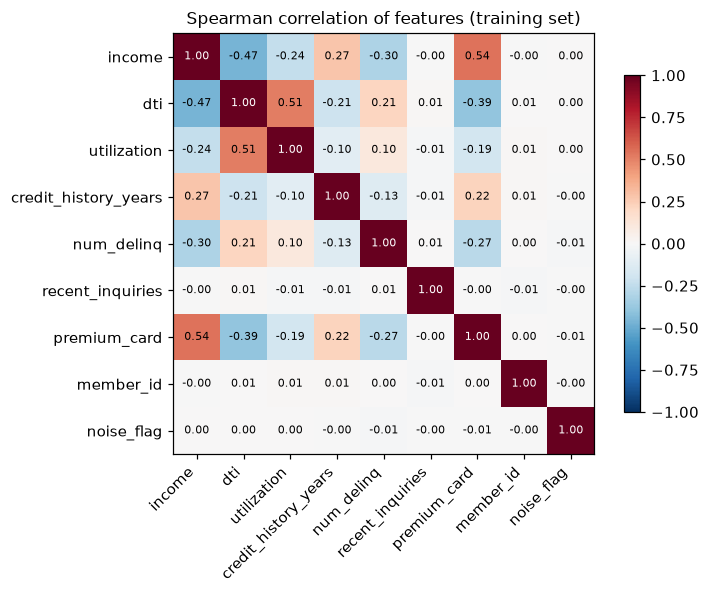

In [3]:
train = np.arange(n) < 15_000
X_train, X_test = X[train], X[~train]
y_train, y_test = y[train], y[~train]
h_test, p_true_test = h[~train], p_true[~train]

rho = spearmanr(X_train).statistic
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(rho, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=45, ha="right")
ax.set_yticks(range(len(FEATURES)), FEATURES)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{rho[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(rho[i, j]) > 0.6 else "black")
ax.set_title("Spearman correlation of features (training set)")
ax.grid(False)
fig.colorbar(im, shrink=0.8)
plt.tight_layout()
plt.show()

Note the correlated block `{income, dti, premium_card, num_delinq, ...}` — all children of the
same latent `h`. Real credit (and product, and marketing) data always looks like this:
features are many noisy views of a few latent factors. Every importance pathology below is
downstream of that fact.

## 2. Importance is method-dependent

### 2.1 Impurity / gain importance loves high-cardinality noise

Impurity importance (MDI in random forests) and gain importance (GBMs) sum the training-loss
reduction over all splits on a feature. Two structural biases:

1. **More split points = more lottery tickets.** A feature with many distinct values offers
   thousands of candidate thresholds. Some look good *on the training sample* by chance, the
   tree takes them, and the spurious gain is booked as importance. A binary noise flag offers
   one candidate split and wins no lotteries.
2. **It is computed on training data**, so it measures what the model *used* (overfitting
   included), not what generalizes.

`member_id` and `noise_flag` carry identical information about default: none. Watch what
impurity-style importance does with them.

In [4]:
model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                           random_state=42, verbosity=-1)
model.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=120, n_jobs=4, random_state=42)
rf.fit(X_train, y_train)

auc_lgb = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
auc_rf = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])
auc_oracle = roc_auc_score(y_test, p_true_test)   # AUC of the true PD — the achievable ceiling
print(f"test AUC:  LightGBM {auc_lgb:.3f}   RandomForest {auc_rf:.3f}   oracle (true PD) {auc_oracle:.3f}")

test AUC:  LightGBM 0.805   RandomForest 0.787   oracle (true PD) 0.831


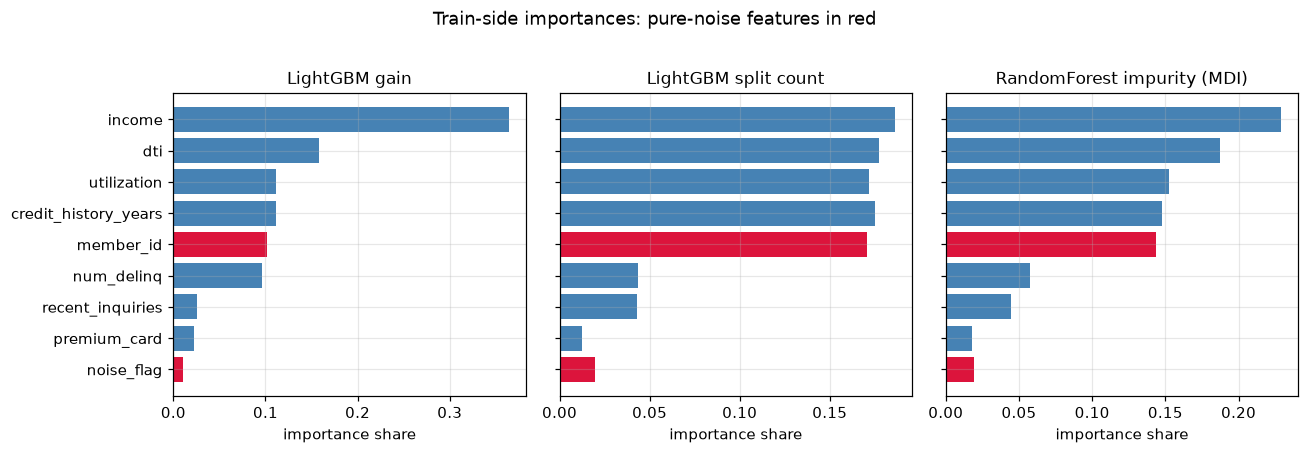

rank of the pure-noise features (1 = most important) under each method:
            lgbm_gain  lgbm_split  rf_impurity_mdi
member_id           5           5                5
noise_flag          9           8                8


In [5]:
imp = pd.DataFrame({
    "lgbm_gain": model.booster_.feature_importance("gain"),
    "lgbm_split": model.booster_.feature_importance("split"),
    "rf_impurity_mdi": rf.feature_importances_,
}, index=FEATURES)
imp = imp / imp.sum()  # normalize each column to shares

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
order = imp["lgbm_gain"].sort_values().index
colors = ["crimson" if f in ("member_id", "noise_flag") else "steelblue" for f in order]
for ax, col, title in zip(axes, imp.columns,
                          ["LightGBM gain", "LightGBM split count", "RandomForest impurity (MDI)"]):
    ax.barh(order, imp.loc[order, col], color=colors)
    ax.set_title(title)
    ax.set_xlabel("importance share")
fig.suptitle("Train-side importances: pure-noise features in red", y=1.02)
plt.tight_layout()
plt.show()

print("rank of the pure-noise features (1 = most important) under each method:")
print(imp.rank(ascending=False).loc[["member_id", "noise_flag"]].astype(int))

`member_id` — a random unique integer — collects a hefty share of importance under all three
train-side methods, out-ranking genuinely predictive features like `recent_inquiries` and
`premium_card`, while `noise_flag` (equally uninformative, but binary) sits at the bottom.
Same information content, wildly different "importance": the ranking is a property of **the
method**, not of the data.

Two practical corollaries:

- An ID-like column near the top of the default importance plot is *also* the classic leakage
  smell (`../04_ml_tabular/02_leakage_validation.ipynb`): either noise being overfit, or worse,
  an encoding of the label via the data pipeline. Either way: investigate, never celebrate.
- Gain importance remains fine as a quick "what is the model spending splits on" diagnostic.
  It is not a statement about the world, and it should not be *the* feature importance in a
  model card.

### 2.2 Permutation importance: held-out, model-agnostic, honest about noise

Permutation importance asks a different question: *how much does held-out performance drop
when we destroy this feature's relationship with everything else* (by shuffling the column)?
Because it is computed on test data against the actual metric, spurious train-side gain is
invisible to it.

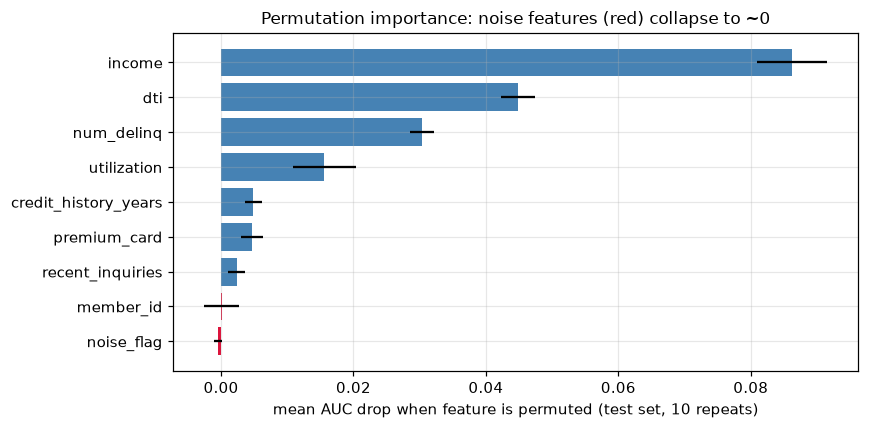

                      mean_auc_drop    std
income                       0.0862 0.0053
dti                          0.0449 0.0026
num_delinq                   0.0303 0.0018
utilization                  0.0156 0.0047
credit_history_years         0.0049 0.0013
premium_card                 0.0047 0.0017
recent_inquiries             0.0023 0.0013
member_id                    0.0001 0.0026
noise_flag                  -0.0004 0.0006


In [6]:
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=42, n_jobs=4)
perm_imp = pd.DataFrame({"mean_auc_drop": perm.importances_mean,
                         "std": perm.importances_std}, index=FEATURES).sort_values("mean_auc_drop")

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["crimson" if f in ("member_id", "noise_flag") else "steelblue" for f in perm_imp.index]
ax.barh(perm_imp.index, perm_imp["mean_auc_drop"], xerr=perm_imp["std"], color=colors)
ax.set_xlabel("mean AUC drop when feature is permuted (test set, 10 repeats)")
ax.set_title("Permutation importance: noise features (red) collapse to ~0")
plt.tight_layout()
plt.show()
print(perm_imp.sort_values("mean_auc_drop", ascending=False).round(4))

Both noise features collapse to ≈ 0, as they should. Problem solved? Not quite — permutation
importance has its own structural blind spot.

### 2.3 The permutation caveat: shuffling creates impossible rows

Permuting a column destroys its *joint* distribution with every other column. When features
are correlated, the model is then evaluated on rows that **cannot occur** — its behavior
there is untested extrapolation. Below: the observed `(dti, utilization)` cloud versus the
cloud after independently permuting `utilization`.

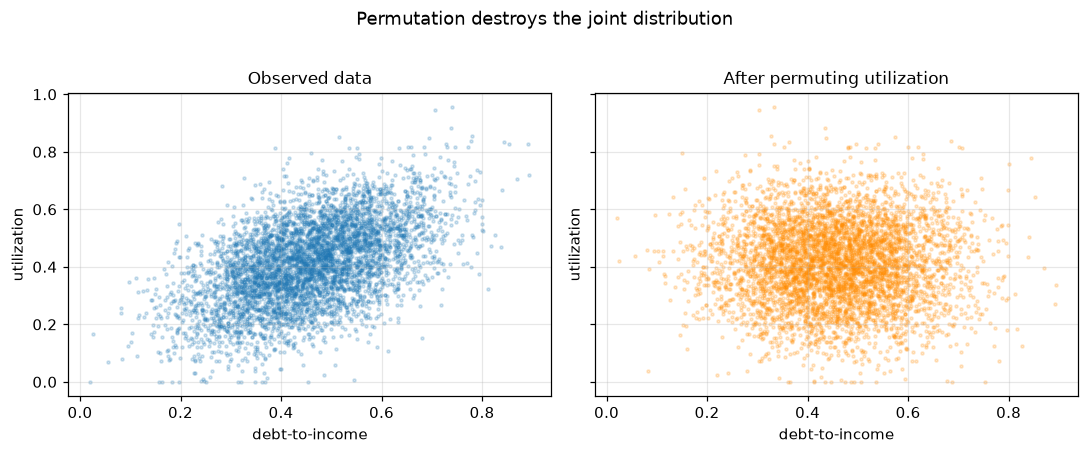

rows outside the ±3σ band around the structural dti→utilization relationship:
  observed:  0.3%
  permuted:  2.6%   <- impossible applicants


In [7]:
util_perm = rng.permutation(X_test["utilization"].to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
axes[0].scatter(X_test["dti"], X_test["utilization"], s=4, alpha=0.2)
axes[0].set_title("Observed data")
axes[1].scatter(X_test["dti"], util_perm, s=4, alpha=0.2, color="darkorange")
axes[1].set_title("After permuting utilization")
for ax in axes:
    ax.set_xlabel("debt-to-income")
    ax.set_ylabel("utilization")
plt.suptitle("Permutation destroys the joint distribution", y=1.02)
plt.tight_layout()
plt.show()

resid_obs = X_test["utilization"] - (0.14 + 0.60 * X_test["dti"])
resid_perm = util_perm - (0.14 + 0.60 * X_test["dti"])
band = 3 * 0.12  # 3 sigma of the structural noise in the dti -> utilization equation
print("rows outside the ±3σ band around the structural dti→utilization relationship:")
print(f"  observed:  {(resid_obs.abs() > band).mean():.1%}")
print(f"  permuted:  {(np.abs(resid_perm) > band).mean():.1%}   <- impossible applicants")

Consequences worth being able to recite:

- **Off-manifold evaluation**: part of the "importance" measures the model's arbitrary
  behavior on impossible rows (a low-DTI applicant with maxed-out cards).
- **Credit hiding**: if two features are near-duplicates, permuting either one barely hurts —
  the untouched twin covers for it — so a critical *concept* can look dispensable
  (demonstrated in section 4).
- It measures importance **to this fitted model**, not predictive value in the data: a feature
  the model ignored scores zero even if it is a perfect substitute for what the model did use.

## 3. SHAP: one attribution framework with guarantees

### 3.1 Shapley values in a few lines

Treat one prediction's features as **players in a cooperative game** whose payout is
$f(x) - E[f(X)]$: this prediction's distance from the average. The Shapley value of feature
$j$ is its average marginal contribution over all orders in which players could join:

$$\phi_j = \sum_{S \subseteq F \setminus \{j\}} \frac{|S|!\,(|F|-|S|-1)!}{|F|!}\,
\left[v(S \cup \{j\}) - v(S)\right],$$

where $v(S)$ is the expected model output when only the features in $S$ are known. It is the
*unique* attribution satisfying **efficiency** (contributions sum exactly to $f(x) - E[f(X)]$),
**symmetry** (interchangeable features get equal credit), **dummy** (an unused feature gets
0), and **additivity**. Exact computation is exponential in general; **TreeSHAP** exploits
tree structure to compute exact values in polynomial time — the reason SHAP and gradient
boosting became a package deal.

Two things to keep straight in practice:

- For a LightGBM classifier, TreeSHAP explains the **raw margin (log-odds)**, not the
  probability; additivity holds on the log-odds scale (pitfall 2 shows why this matters).
- $v(S)$ requires filling in the "unknown" features somehow. Path-dependent TreeSHAP (the
  default here) uses the trees' own training cover; the interventional variant averages over
  an explicit background dataset. Under correlated features they can differ — exercise 3
  exploits this.

In [8]:
explainer = shap.TreeExplainer(model)
sv = explainer(X_test)   # Explanation object: values are log-odds contributions

raw_margin = model.booster_.predict(X_test, raw_score=True)
additivity_err = np.abs(sv.values.sum(axis=1) + sv.base_values - raw_margin).max()
base_value = float(np.ravel(sv.base_values)[0])
print(f"SHAP matrix shape: {sv.values.shape}  (rows × features, log-odds units)")
print(f"base value (average training log-odds): {base_value:.3f} -> p = {expit(base_value):.3f}")
print(f"local accuracy: max |sum(SHAP) + base - raw margin| = {additivity_err:.2e}")

SHAP matrix shape: (5000, 9)  (rows × features, log-odds units)
base value (average training log-odds): -2.362 -> p = 0.086
local accuracy: max |sum(SHAP) + base - raw margin| = 2.13e-14


### 3.2 Global view: the beeswarm

Each dot is one applicant × one feature; x = SHAP value (pushing toward default → right),
color = the feature's value. This is the most information-dense importance plot available:
magnitude, direction, and nonlinearity in one figure.

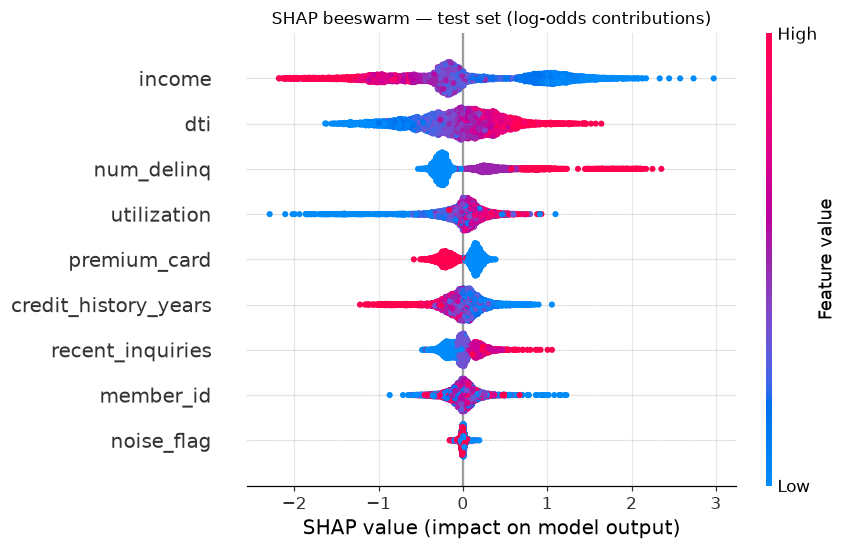

In [9]:
shap.plots.beeswarm(sv, max_display=9, show=False)
plt.title("SHAP beeswarm — test set (log-odds contributions)")
plt.tight_layout()
plt.show()

Reading it like a senior candidate:

- `dti`, `utilization`, `num_delinq`: high values (red) push right — monotone and directionally
  sensible, as planted. `income` dominates: partly its real causal role (the interaction), but
  mostly because it is the model's best available proxy for latent financial health.
- `premium_card` earns solid mid-pack SHAP credit. The model is *right* to use it — it carries
  incremental signal about `h` beyond noisy income — and SHAP faithfully reports that. SHAP
  describes the model; it cannot know the feature is causally inert. Section 5 makes that
  sting.
- `member_id` sits near — but not at — zero, well above `noise_flag`. SHAP explains *this
  fitted model*, and this model genuinely spent overfit splits on `member_id`. SHAP importance
  is not statistical significance; it inherits whatever the model learned, noise included.

### 3.3 Dependence plot with interaction coloring

We planted an interaction: utilization hurts low-income applicants more. A SHAP dependence
plot — SHAP value of utilization against its own value, colored by income — shows it as
vertically separated, differently sloped bands.

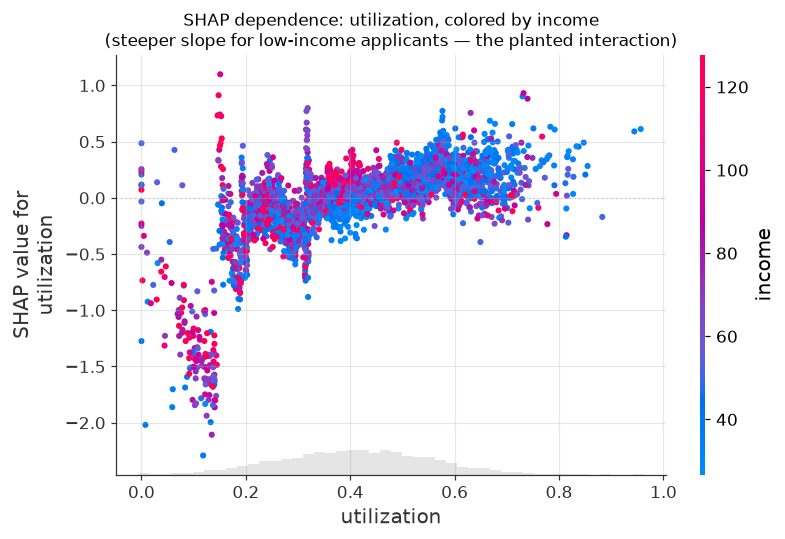

In [10]:
shap.plots.scatter(sv[:, "utilization"], color=sv[:, "income"], show=False)
plt.title("SHAP dependence: utilization, colored by income\n(steeper slope for low-income applicants — the planted interaction)")
plt.tight_layout()
plt.show()

Vertical spread at a fixed utilization *is* interaction: the same utilization moves different
applicants' log-odds by different amounts, and the coloring reveals with what. (Exercise 2
checks this pair against exact SHAP interaction values — with a twist.)

### 3.4 Local explanation: one declined application

Suppose the lender declines when predicted PD ≥ 25% (where to put that threshold is an
economics question — `../04_ml_tabular/03_evaluation_calibration.ipynb`). We take one declined
applicant and ask the question the customer, the ops reviewer, and the regulator all ask:
**why this decision?**

In [11]:
pd_test = model.predict_proba(X_test)[:, 1]
DECLINE_AT = 0.25
declined_idx = np.flatnonzero(pd_test >= DECLINE_AT)
print(f"declined: {len(declined_idx):,} of {len(X_test):,} applicants "
      f"({len(declined_idx) / len(X_test):.1%})")

# a representative decline: the median-PD applicant among the declined
applicant = declined_idx[np.argsort(pd_test[declined_idx])[len(declined_idx) // 2]]
print(f"\napplicant #{applicant}: predicted PD = {pd_test[applicant]:.1%}  (decline threshold {DECLINE_AT:.0%})")
print(X_test.iloc[applicant].round(2))

declined: 998 of 5,000 applicants (20.0%)

applicant #954: predicted PD = 40.5%  (decline threshold 25%)
income                     44.4300
dti                         0.3100
utilization                 0.3500
credit_history_years        2.2000
num_delinq                  2.0000
recent_inquiries            3.0000
premium_card                0.0000
member_id              13,865.0000
noise_flag                  1.0000
Name: 15954, dtype: float64


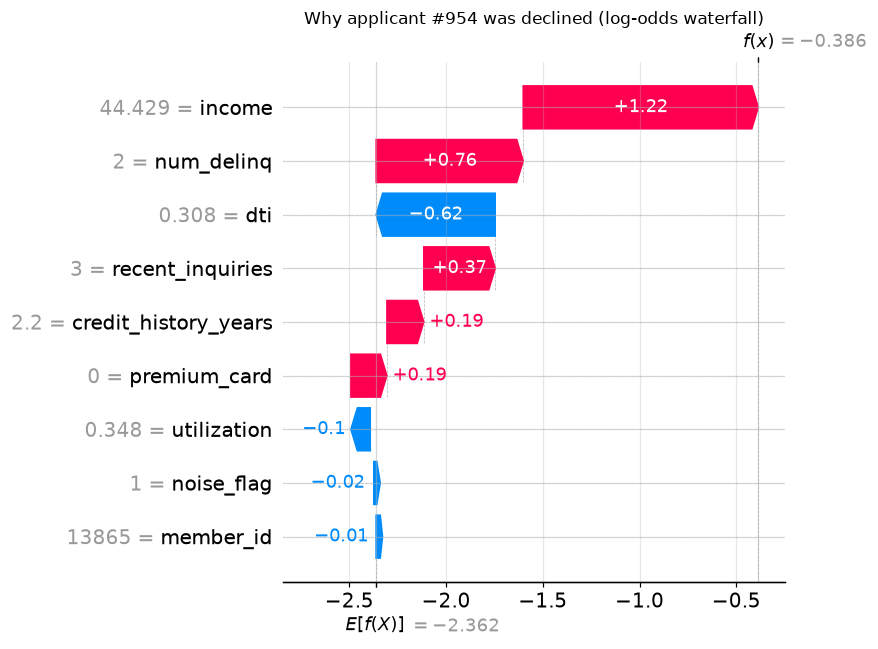

In [12]:
shap.plots.waterfall(sv[applicant], max_display=9, show=False)
plt.title(f"Why applicant #{applicant} was declined (log-odds waterfall)")
plt.tight_layout()
plt.show()

The waterfall walks from the population base rate ($E[f(X)]$, log-odds) to this applicant's
score; each bar is a feature's Shapley contribution and, by the efficiency axiom, the bars sum
*exactly* to the gap. This is the raw material for the adverse-action reason codes in
section 7 — but note the units are log-odds, and "the biggest bar" depends on the reference
population (both revisited later).

## 4. Correlated features: SHAP splits the credit

The symmetry axiom cuts both ways: if two features are near-duplicates, Shapley *must* split
the credit between them — each looks roughly half as important, though the underlying signal
is unchanged. Realistic scenario: `income` (verified, from payroll data) and `income_stated`
(self-reported on the application) — the same quantity with small discrepancies.

test AUC: original 0.805 -> with duplicate 0.805  (information unchanged)


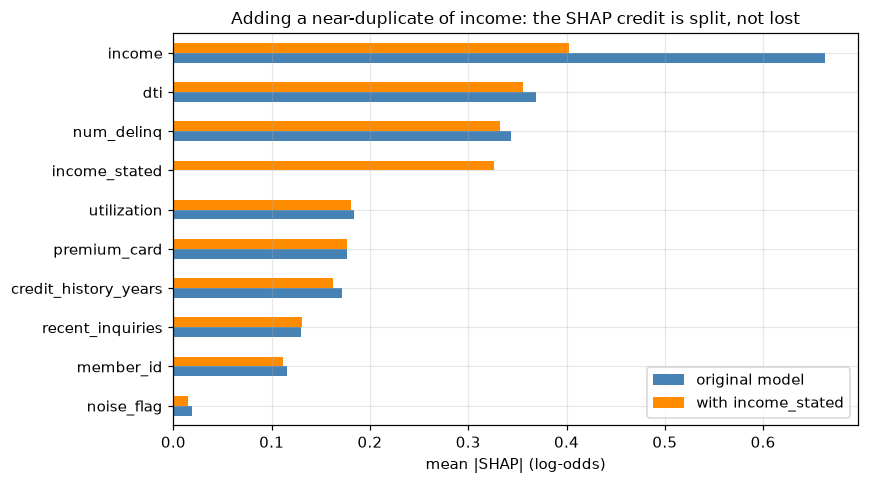

mean|SHAP| income: 0.663 -> 0.403;  income_stated: 0.326;  pair sum: 0.729



permutation AUC-drop: income alone was 0.0862; now income 0.0447, income_stated 0.0155


In [13]:
X_train_dup = X_train.copy()
X_test_dup = X_test.copy()
dup_noise = np.random.default_rng(7)
X_train_dup["income_stated"] = X_train_dup["income"] * np.exp(dup_noise.normal(0, 0.02, len(X_train_dup)))
X_test_dup["income_stated"] = X_test_dup["income"] * np.exp(dup_noise.normal(0, 0.02, len(X_test_dup)))
DUP_FEATURES = list(X_train_dup.columns)

model_dup = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                               random_state=42, verbosity=-1)
model_dup.fit(X_train_dup, y_train)
sv_dup = shap.TreeExplainer(model_dup)(X_test_dup)

auc_dup = roc_auc_score(y_test, model_dup.predict_proba(X_test_dup)[:, 1])
print(f"test AUC: original {auc_lgb:.3f} -> with duplicate {auc_dup:.3f}  (information unchanged)")

mean_abs = pd.DataFrame({
    "original model": pd.Series(np.abs(sv.values).mean(0), index=FEATURES),
    "with income_stated": pd.Series(np.abs(sv_dup.values).mean(0), index=DUP_FEATURES),
}).fillna(0.0)

fig, ax = plt.subplots(figsize=(8, 4.5))
mean_abs.loc[mean_abs.max(axis=1).sort_values().index].plot.barh(ax=ax, color=["steelblue", "darkorange"])
ax.set_xlabel("mean |SHAP| (log-odds)")
ax.set_title("Adding a near-duplicate of income: the SHAP credit is split, not lost")
plt.tight_layout()
plt.show()

i0 = mean_abs.loc["income", "original model"]
i1 = mean_abs.loc["income", "with income_stated"]
s1 = mean_abs.loc["income_stated", "with income_stated"]
print(f"mean|SHAP| income: {i0:.3f} -> {i1:.3f};  income_stated: {s1:.3f};  pair sum: {i1 + s1:.3f}")

perm_dup = permutation_importance(model_dup, X_test_dup, y_test, scoring="roc_auc",
                                  n_repeats=10, random_state=42, n_jobs=4)
perm_dup_s = pd.Series(perm_dup.importances_mean, index=DUP_FEATURES)
print(f"\npermutation AUC-drop: income alone was {perm_imp.loc['income', 'mean_auc_drop']:.4f}; "
      f"now income {perm_dup_s['income']:.4f}, income_stated {perm_dup_s['income_stated']:.4f}")

Both methods now understate the *concept*: SHAP splits income's credit roughly in half across
the pair (their sum ≈ the original), and permutation importance craters for each individually
because the untouched twin covers for the shuffled one. No method is "wrong" — each answers
its narrow question about *this column in this model* — but a stakeholder reading the chart
concludes "income matters half as much as last quarter", which is false.

### The remedy: grouped / clustered importance

Stop asking about columns; ask about **concepts**. Cluster features by statistical dependence,
then attribute at the cluster level: sum |SHAP| within clusters, and permute whole clusters
jointly (the same row shuffle for every member, which preserves within-group structure).

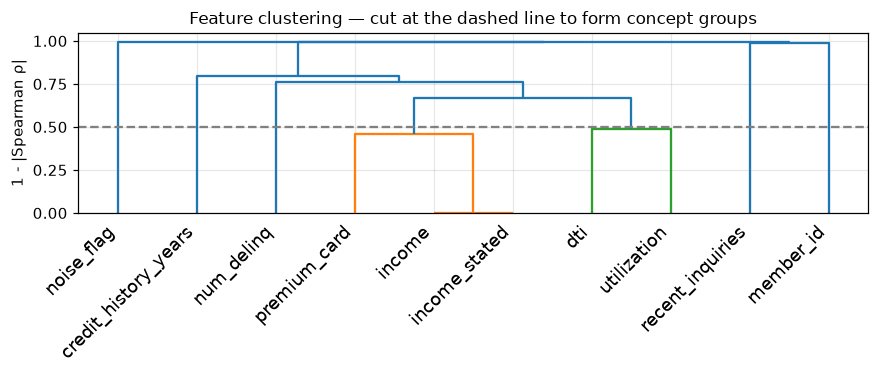

multi-feature concept groups at |ρ| > 0.5:
   income + premium_card + income_stated
   dti + utilization



grouped importance (duplicate-feature model):
                                       joint AUC drop  sum |SHAP|
income + premium_card + income_stated          0.1189      0.9057
dti + utilization                              0.0595      0.5363


In [14]:
rho_dup = spearmanr(X_train_dup).statistic
dist = 1 - np.abs(rho_dup)
np.fill_diagonal(dist, 0.0)
link = linkage(squareform(dist, checks=False), method="average")

fig, ax = plt.subplots(figsize=(8, 3.5))
dendrogram(link, labels=DUP_FEATURES, ax=ax, color_threshold=0.5)
ax.axhline(0.5, ls="--", color="gray")
ax.set_ylabel("1 - |Spearman ρ|")
ax.set_title("Feature clustering — cut at the dashed line to form concept groups")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

cluster_ids = fcluster(link, t=0.5, criterion="distance")
clusters: dict = {}
for c, f in zip(cluster_ids, DUP_FEATURES):
    clusters.setdefault(c, []).append(f)
groups = {" + ".join(v): v for v in clusters.values() if len(v) > 1}
print("multi-feature concept groups at |ρ| > 0.5:")
for g in groups:
    print("  ", g)


def grouped_permutation_importance(model, Xe, ye, groups, n_repeats=10, seed=42):
    """Permute all columns of a group with the SAME row permutation -> joint importance."""
    r = np.random.default_rng(seed)
    base = roc_auc_score(ye, model.predict_proba(Xe)[:, 1])
    out = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = Xe.copy()
            idx = r.permutation(len(Xe))
            Xp[cols] = Xe[cols].to_numpy()[idx]
            drops.append(base - roc_auc_score(ye, model.predict_proba(Xp)[:, 1]))
        out[name] = float(np.mean(drops))
    return pd.Series(out, name="joint AUC drop").sort_values(ascending=False)


grouped_pi = grouped_permutation_importance(model_dup, X_test_dup, y_test, groups)
shap_by_group = pd.Series(
    {name: mean_abs.loc[cols, "with income_stated"].sum() for name, cols in groups.items()},
    name="sum |SHAP|")
print("\ngrouped importance (duplicate-feature model):")
print(pd.concat([grouped_pi, shap_by_group], axis=1).round(4))

Two things happened, both instructive:

1. The income *concept* recovers its full importance once its columns are permuted together
   and their SHAP summed — compare the joint AUC drop with the two individual drops above.
2. The clustering pulled `premium_card` into the income group on its own: statistically it is
   another view of the same "affluence / financial health" concept. Clustered importance
   quietly did the confounder-detection work that column-level views hide.

In production dashboards, report grouped importances with stable, named concepts
("indebtedness", "payment history") — column-level importance is too brittle under routine
feature-set churn to trend over time.

## 5. Importance is NOT causality

`premium_card` holders default at a quarter of the rate of others, and the feature earns solid
SHAP credit... so should risk ops hand free premium-card upgrades to risky customers to make
them safer? Obviously not — and because we own the structural equations, we can *demonstrate*
the obviously.

We compare two numbers per intervention:

1. **What the model implies** if you naively feed the modified feature in: "predicted PD if we
   set premium_card = 1 for everyone".
2. **What actually happens**: re-run the true structural model under the intervention — a
   `do()` operation (`../03_causal_inference/01_potential_outcomes_dags.ipynb`).

In [15]:
def implied_vs_true(X_mod: pd.DataFrame, label: str) -> dict:
    """Model-implied mean PD after modifying features vs true causal mean PD."""
    return {
        "intervention": label,
        "model-implied PD": model.predict_proba(X_mod)[:, 1].mean(),
        "true causal PD": expit(true_log_odds(X_mod, h_test)).mean(),
    }


X_do_premium = X_test.copy()
X_do_premium["premium_card"] = 1

X_do_util = X_test.copy()
X_do_util["utilization"] = X_do_util["utilization"] * 0.5   # e.g. proactive credit-line increases

interventions = pd.DataFrame([
    {"intervention": "(baseline)", "model-implied PD": pd_test.mean(), "true causal PD": p_true_test.mean()},
    implied_vs_true(X_do_premium, "do(premium_card := 1)"),
    implied_vs_true(X_do_util, "do(utilization := 0.5 x utilization)"),
]).set_index("intervention")
interventions["model-implied Δ"] = interventions["model-implied PD"] - pd_test.mean()
interventions["true causal Δ"] = interventions["true causal PD"] - p_true_test.mean()
print(interventions.round(4))

                                      model-implied PD  true causal PD  model-implied Δ  true causal Δ
intervention                                                                                          
(baseline)                                      0.1491          0.1486           0.0000         0.0000
do(premium_card := 1)                           0.1273          0.1486          -0.0218         0.0000
do(utilization := 0.5 x utilization)            0.1144          0.1156          -0.0347        -0.0330


The model promises a sizable default-rate reduction from handing out premium cards; reality
delivers a true causal Δ of **exactly zero** — the association ran entirely through the
confounder `h` (financial health causes both card ownership and repayment). Intervening on
`utilization`, which really is causal, moves both columns, and by similar amounts.

The one-liner to internalize: **a predictive model answers "what do we expect given that we
observed x?"; a decision to change x asks "what happens if we make x different?" —
conditioning vs intervening.** Every importance flavor — gain, permutation, SHAP — lives
strictly in the first world. Nothing *in the training data* distinguishes `premium_card` from
`utilization`; only causal knowledge (a DAG, an experiment) can.

What acting on features properly looks like:

- Randomize the intervention: A/B test the credit-line increase
  (`../02_ab_testing/01_ab_test_end_to_end.ipynb`).
- Or estimate the effect from observational data under explicit identification assumptions
  (`../03_causal_inference/02_propensity_ipw_doubly_robust.ipynb`).
- If the question is *whom* to treat, model the treatment effect itself, not the risk score
  (`../03_causal_inference/05_uplift_cate.ipynb`).

## 6. PDP and ICE — and their extrapolation trap

A **partial dependence plot** sweeps one feature over a grid, holds each row's other features
fixed, and averages the predictions: $\widehat{PD}_j(v) = \frac{1}{n}\sum_i f(v, x_i^{(-j)})$.
**ICE** plots the per-row curves before averaging. Two failure modes to know cold:

1. **Averaging hides heterogeneity**: if the effect differs by segment (an interaction), the
   mean curve represents nobody.
2. **Extrapolation**: the grid value $v$ is combined with *every* row's other features —
   including rows where that combination is impossible. Under correlated features much of the
   average is computed off-manifold, where the model was never trained.

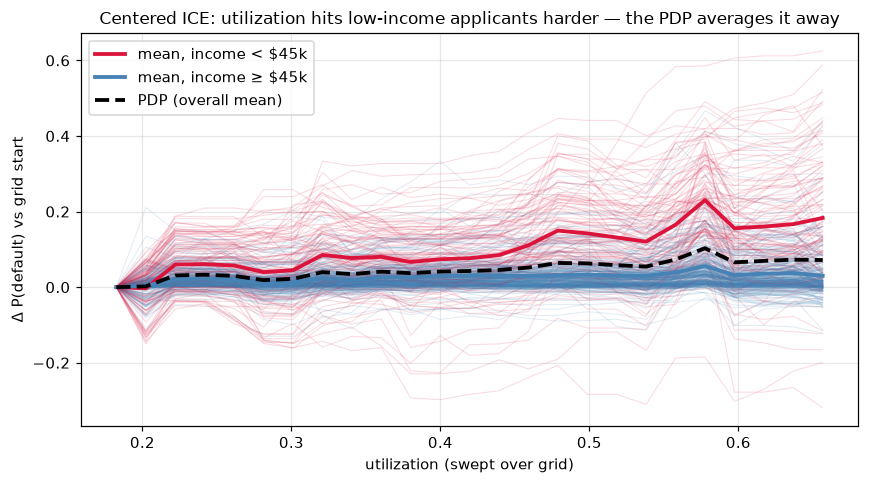

predicted-PD rise over the full utilization sweep: low income +0.183, higher income +0.030  (6.1x)


In [16]:
sample = X_test.iloc[:400]
pd_res = partial_dependence(model, sample, ["utilization"], kind="both", grid_resolution=25)
grid = pd_res["grid_values"][0]
ice = pd_res["individual"][0]          # (n_rows, n_grid), P(default)
ice_c = ice - ice[:, [0]]              # centered ICE: rise relative to the grid start
low_inc = (sample["income"] < 45).to_numpy()

fig, ax = plt.subplots(figsize=(8, 4.5))
for i in range(len(sample)):
    ax.plot(grid, ice_c[i], color="crimson" if low_inc[i] else "steelblue", alpha=0.15, lw=0.7)
ax.plot(grid, ice_c[low_inc].mean(0), color="crimson", lw=2.5, label="mean, income < $45k")
ax.plot(grid, ice_c[~low_inc].mean(0), color="steelblue", lw=2.5, label="mean, income ≥ $45k")
ax.plot(grid, ice_c.mean(0), color="black", lw=2.5, ls="--", label="PDP (overall mean)")
ax.set_xlabel("utilization (swept over grid)")
ax.set_ylabel("Δ P(default) vs grid start")
ax.set_title("Centered ICE: utilization hits low-income applicants harder — the PDP averages it away")
ax.legend()
plt.tight_layout()
plt.show()

rise_low = ice_c[low_inc, -1].mean()
rise_high = ice_c[~low_inc, -1].mean()
print(f"predicted-PD rise over the full utilization sweep: low income {rise_low:+.3f}, "
      f"higher income {rise_high:+.3f}  ({rise_low / rise_high:.1f}x)")

The ICE fan splits into two bundles — the planted income × utilization interaction — while
the dashed PDP reports a compromise slope that is right for no one. (The probability-scale
ratio above overstates the log-odds interaction somewhat: low-income applicants also start at
higher base risk, where the logistic curve is steeper — units again.) Rule of thumb: never
show a PDP without having looked at the ICE curves behind it.

### The extrapolation trap, quantified

Now the duplicate-income model from section 4. Sweeping `income` alone while `income_stated`
keeps its observed value manufactures applicants whose two income measurements wildly
disagree — rows that cannot exist. The PDP becomes a poll of the model's undefined
off-manifold behavior.

probing income = $150k while income_stated stays observed: the two income fields disagree by >1.5x for 88% of rows -> impossible applicants


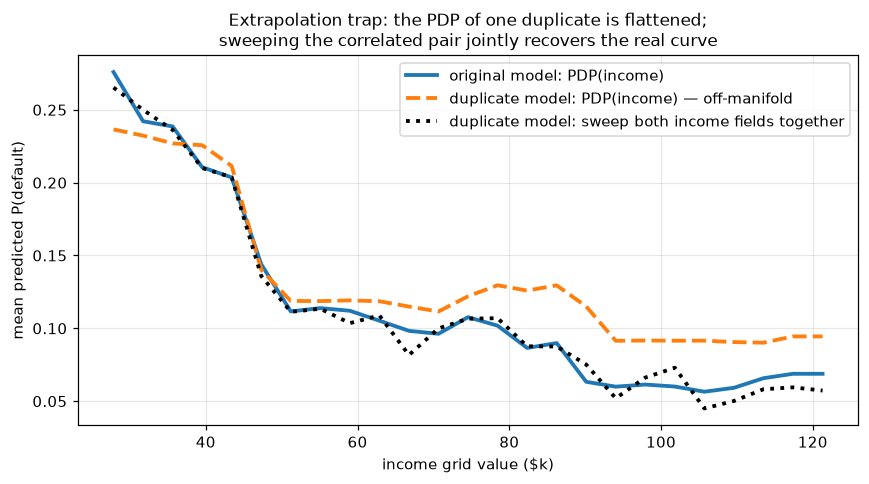

PDP range (max - min predicted PD): original 0.219, duplicate-model income only 0.146, pair swept jointly 0.220


In [17]:
grid_probe = 150.0   # "$150k verified income", stated income left at observed values
disagree = (np.abs(np.log(grid_probe / X_test_dup["income_stated"])) > np.log(1.5)).mean()
print(f"probing income = $150k while income_stated stays observed: the two income fields "
      f"disagree by >1.5x for {disagree:.0%} of rows -> impossible applicants")

pd_single = partial_dependence(model, X_test.iloc[:800], ["income"], kind="average", grid_resolution=25)
pd_dup = partial_dependence(model_dup, X_test_dup.iloc[:800], ["income"], kind="average", grid_resolution=25)

# grouped PDP: sweep BOTH income columns together -> stays on-manifold
grid_d = pd_dup["grid_values"][0]
Xg = X_test_dup.iloc[:800].copy()
grouped_curve = []
for v in grid_d:
    Xg["income"] = v
    Xg["income_stated"] = v
    grouped_curve.append(model_dup.predict_proba(Xg)[:, 1].mean())

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(pd_single["grid_values"][0], pd_single["average"][0], lw=2.5,
        label="original model: PDP(income)")
ax.plot(grid_d, pd_dup["average"][0], lw=2.5, ls="--",
        label="duplicate model: PDP(income) — off-manifold")
ax.plot(grid_d, grouped_curve, lw=2.5, ls=":", color="black",
        label="duplicate model: sweep both income fields together")
ax.set_xlabel("income grid value ($k)")
ax.set_ylabel("mean predicted P(default)")
ax.set_title("Extrapolation trap: the PDP of one duplicate is flattened;\nsweeping the correlated pair jointly recovers the real curve")
ax.legend()
plt.tight_layout()
plt.show()

print(f"PDP range (max - min predicted PD): original {np.ptp(pd_single['average'][0]):.3f}, "
      f"duplicate-model income only {np.ptp(pd_dup['average'][0]):.3f}, "
      f"pair swept jointly {np.ptp(np.asarray(grouped_curve)):.3f}")

The dashed curve — the PDP a standard tool happily hands you — flattens the income effect,
because at every off-manifold grid point the model leans on the *other*, untouched income
field. Sweeping the correlated group together restores the truthful curve: the PDP analogue of
grouped permutation importance, same medicine. (The other standard remedy is **ALE** —
accumulated local effects — which averages *local* finite differences over data-supported
neighborhoods only; know the name and the idea for interviews.)

## 7. Stakeholder translation

An explanation that stays in the notebook has zero business value. Two translation targets, in
increasing order of formality.

### 7.1 The action memo

Generated from the numbers computed above. Note the shape: *finding → so-what → recommended
action*, with an honest label on what is causal knowledge and what is merely predictive.

In [18]:
top3 = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False).head(3)
median_row = X_test.median().to_frame().T.astype(X_test.dtypes)
hi, lo = median_row.copy(), median_row.copy()
hi["utilization"], lo["utilization"] = 0.8, 0.4
pd_hi = model.predict_proba(hi)[0, 1]
pd_lo = model.predict_proba(lo)[0, 1]

memo = f"""
MEMO - Credit default model: what drives risk scores, and what to do about it
-----------------------------------------------------------------------------
Model: LightGBM, test AUC {auc_lgb:.2f}. Declines at PD >= {DECLINE_AT:.0%} affect {len(declined_idx) / len(X_test):.0%} of applicants.

1. WHAT THE SCORE REACTS TO (SHAP, held-out data): {top3.index[0]}, {top3.index[1]},
   {top3.index[2]} are the top drivers. For a typical applicant, utilization of
   0.8 vs 0.4 scores PD {pd_hi:.0%} vs {pd_lo:.0%}.

2. SEGMENT FINDING: rising utilization raises predicted PD ~{rise_low / rise_high:.0f}x more for
   applicants under $45k income ({(income < 45).mean():.0%} of the book). Utilization-based
   outreach should be prioritized by segment, not one global cutoff.

3. CAUTION - PREDICTIVE IS NOT ACTIONABLE: premium_card ranks mid-pack in the model,
   and its holders default at 1/4 the rate of others, but it is a proxy for underlying
   financial health. Upgrading risky customers to premium cards would change nothing
   (verified against the data-generating process in section 5). Do not ship it.

4. RECOMMENDED ACTION: pilot proactive credit-line increases (mechanically lower
   utilization) as a RANDOMIZED test on the high-sensitivity segment; measure realized
   12-month default, not the model score. The model motivates the hypothesis; only the
   experiment licenses the rollout.
"""
print(memo)


MEMO - Credit default model: what drives risk scores, and what to do about it
-----------------------------------------------------------------------------
Model: LightGBM, test AUC 0.80. Declines at PD >= 25% affect 20% of applicants.

1. WHAT THE SCORE REACTS TO (SHAP, held-out data): income, dti,
   num_delinq are the top drivers. For a typical applicant, utilization of
   0.8 vs 0.4 scores PD 7% vs 8%.

2. SEGMENT FINDING: rising utilization raises predicted PD ~6x more for
   applicants under $45k income (29% of the book). Utilization-based
   outreach should be prioritized by segment, not one global cutoff.

3. CAUTION - PREDICTIVE IS NOT ACTIONABLE: premium_card ranks mid-pack in the model,
   and its holders default at 1/4 the rate of others, but it is a proxy for underlying
   financial health. Upgrading risky customers to premium cards would change nothing
   (verified against the data-generating process in section 5). Do not ship it.

4. RECOMMENDED ACTION: pilot proactive 

### 7.2 Regulated context: adverse-action reason codes

In US consumer credit (ECOA / Regulation B, FCRA), a declined applicant must be told the
**principal reasons** for the decision — specific, ranked, and derived from the actual scoring
model. Top-negative-SHAP has become a standard way to generate them; the scorecard world this
grew out of is covered in `../09_finance_and_operations/01_credit_scorecard.ipynb`. Reason
codes for our declined applicant from section 3.4:

In [19]:
REASON_TEXT = {
    "utilization": "Proportion of balances to credit limits is too high on revolving accounts",
    "dti": "Debt-to-income ratio is too high",
    "num_delinq": "Delinquency on accounts",
    "recent_inquiries": "Too many recent credit inquiries",
    "credit_history_years": "Length of credit history is insufficient",
    "income": "Income is insufficient for the amount of credit requested",
    "premium_card": "(affluence proxy - NOT a defensible reason code)",
    "member_id": "(internal ID / noise - NOT a defensible reason code)",
    "noise_flag": "(noise - NOT a defensible reason code)",
}

contrib = pd.Series(sv.values[applicant], index=FEATURES).sort_values(ascending=False)
print(f"Adverse-action reasons, applicant #{applicant} (PD {pd_test[applicant]:.0%}):\n")
for rank, (feat, val) in enumerate(contrib.head(4).items(), 1):
    print(f"  {rank}. {REASON_TEXT[feat]:<72s} [SHAP +{val:.2f}]")

# how often would a NON-defensible feature surface as a principal reason across the book?
bad_idx = [FEATURES.index(f) for f in ("premium_card", "member_id", "noise_flag")]
top4_all = np.argsort(-sv.values[declined_idx], axis=1)[:, :4]
share_bad = np.isin(top4_all, bad_idx).any(axis=1).mean()
print(f"\nportfolio audit: {share_bad:.0%} of declined applicants would have a proxy or noise "
      f"feature\namong their top-4 SHAP reasons under this feature set.")

Adverse-action reasons, applicant #954 (PD 40%):

  1. Income is insufficient for the amount of credit requested                [SHAP +1.22]
  2. Delinquency on accounts                                                  [SHAP +0.76]
  3. Too many recent credit inquiries                                         [SHAP +0.37]
  4. Length of credit history is insufficient                                 [SHAP +0.19]

portfolio audit: 63% of declined applicants would have a proxy or noise feature
among their top-4 SHAP reasons under this feature set.


That audit number is the punchline: with this (deliberately sloppy) feature set, a large share
of adverse-action letters would cite an affluence proxy or an internal ID. Senior-level
caveats you are expected to volunteer:

- **The feature set is the compliance surface.** If `member_id` or `premium_card` can surface
  as a top reason, the *features* are wrong, not the explanation method. In regulated models
  this constraint belongs in feature selection, before training — one reason scorecard shops
  restrict to monotone, interpretable features (LightGBM supports monotonic constraints:
  `../04_ml_tabular/01_gradient_boosting_mastery.ipynb`).
- **The reference matters.** SHAP is contrastive: "+0.9 log-odds *relative to the average
  applicant*". Against a different background (approved applicants, the applicant's segment),
  the reason ranking can change. Choose a reference population, justify it, document it,
  freeze it. Exercise 3 shows the sensitivity.
- **Explanations need monitoring too**: a drifting SHAP distribution is an early warning that
  the model's reasoning changed even while AUC holds
  (`../10_ml_in_production/01_drift_monitoring.ipynb`).

## 8. Pitfalls

### Pitfall 1: permutation importance on the *training* set

Held-out evaluation was doing heavy lifting in section 2.2. Compute permutation importance on
training data with an overfit model and the noise ID looks important again — destroying
`member_id` genuinely does hurt the *training* fit of a model that memorized with it.

In [20]:
overfit = lgb.LGBMClassifier(n_estimators=150, learning_rate=0.1, num_leaves=127,
                             min_child_samples=2, random_state=42, verbosity=-1)
overfit.fit(X_train, y_train)
print(f"overfit model AUC: train {roc_auc_score(y_train, overfit.predict_proba(X_train)[:, 1]):.3f}, "
      f"test {roc_auc_score(y_test, overfit.predict_proba(X_test)[:, 1]):.3f}")

pi_tr = permutation_importance(overfit, X_train.iloc[:4000], y_train[:4000], scoring="roc_auc",
                               n_repeats=5, random_state=42, n_jobs=4)
pi_te = permutation_importance(overfit, X_test, y_test, scoring="roc_auc",
                               n_repeats=5, random_state=42, n_jobs=4)
cmp = pd.DataFrame({"perm. importance on TRAIN": pi_tr.importances_mean,
                    "perm. importance on TEST": pi_te.importances_mean}, index=FEATURES)
print(cmp.sort_values("perm. importance on TRAIN", ascending=False).round(4))

overfit model AUC: train 1.000, test 0.792


                      perm. importance on TRAIN  perm. importance on TEST
income                                   0.1307                    0.0898
dti                                      0.0969                    0.0524
utilization                              0.0528                    0.0168
credit_history_years                     0.0499                    0.0081
member_id                                0.0490                   -0.0003
num_delinq                               0.0261                    0.0314
recent_inquiries                         0.0054                    0.0024
premium_card                             0.0024                    0.0050
noise_flag                               0.0002                    0.0004


On the training set `member_id` beats genuinely predictive features; on the test set it
collapses to ~zero. Same estimator, same method — the only difference is which data you
asked. **Importance for generalization must be measured on data the model never saw.**

### Pitfall 2: forgetting the units — log-odds is not probability

TreeSHAP for a classifier explains log-odds. The *same* SHAP contribution translates into very
different probability changes depending on where the applicant sits on the logistic curve:

In [21]:
shap_contrib = 0.7   # a typical strong feature contribution, in log-odds
for base_pd in [0.02, 0.10, 0.50]:
    new_pd = expit(logit(base_pd) + shap_contrib)
    print(f"base PD {base_pd:>4.0%} + 0.7 log-odds -> {new_pd:5.1%}   (Δ = {100 * (new_pd - base_pd):+5.1f} pp)")

base PD   2% + 0.7 log-odds ->  3.9%   (Δ =  +1.9 pp)
base PD  10% + 0.7 log-odds -> 18.3%   (Δ =  +8.3 pp)
base PD  50% + 0.7 log-odds -> 66.8%   (Δ = +16.8 pp)


Quoting "+0.7" to a stakeholder as if it were percentage points misstates the effect by up to
an order of magnitude depending on the segment. Either explain on the probability scale
(interventional TreeSHAP supports `model_output="probability"`; additivity then holds on that
scale, at some compute cost), or translate explicitly at the applicant's own base rate, as the
memo did.

### Pitfall 3: "we dropped it and nothing changed, so it doesn't matter"

In [22]:
cols_no_income = [c for c in DUP_FEATURES if c != "income"]
model_dropped = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                                   random_state=42, verbosity=-1)
model_dropped.fit(X_train_dup[cols_no_income], y_train)
auc_dropped = roc_auc_score(y_test, model_dropped.predict_proba(X_test_dup[cols_no_income])[:, 1])
print(f"duplicate-feature model AUC with verified income: {auc_dup:.3f};  after DROPPING it: {auc_dropped:.3f}")

duplicate-feature model AUC with verified income: 0.805;  after DROPPING it: 0.805


AUC barely moves — `income_stated` still carries the signal. The invalid conclusion ("verified
income doesn't matter for default risk") would misinform the business about one of its most
informative signals. An ablation measures **redundancy given the rest of the feature set**,
not relevance. The grouped view of section 4 is the honest summary — drop the whole income
*cluster* and the AUC would tell a very different story.

## 9. Interview corner

**Q1. Explain SHAP to a PM in two minutes.**
"This customer's score is 30% when the average is 12%. SHAP fairly divides that 18-point gap
among the inputs — like splitting a dinner bill by what each person ordered. Fair means: the
shares always add up exactly to the gap, identical contributors get identical shares, and an
input the model never used gets zero. So I can say, per customer, 'card utilization
contributed most, short credit history second.' Two warnings: it describes how *the model*
thinks, not how the world works — it can't tell us what to change — and the shares are only
as good as the model behind them."

**Q2. Gain importance and permutation importance disagree on a feature — why? What do you check?**
Name the mechanical differences: gain is train-side (inflated by overfitting, biased toward
high-cardinality features); permutation is test-side against one chosen metric. Diagnose by
case: (a) high-cardinality/ID feature with high gain but ~0 permutation → overfitting or
leakage, audit the feature; (b) correlated features → permutation hides credit (the twin
covers) while gain concentrates on whichever column the trees happened to pick;
(c) metric sensitivity — a feature can matter for calibration but not ranking (log loss vs
AUC). Checks: cardinality audit, correlation clusters, train-vs-test comparison, grouped
importance.

**Q3. Feature X tops the churn model's importance. Can we drive X down to reduce churn?**
Not on that evidence — importance is associational; the model conditions, the proposed action
intervenes. X may be a pure proxy for a confounder (our `premium_card`: strong marginal
association, solid SHAP rank, causal effect exactly zero). Proper path: treat the model as
hypothesis generation → check identification (DAG, backdoor paths) → run an experiment or
quasi-experiment → if the question is targeting, model uplift, not risk.

**Q4. Two nearly identical features each get half the SHAP credit. Is SHAP broken?**
No — symmetry *requires* the split; a method giving both full credit would double-count the
total and break additivity. Fix it at the representation level: deduplicate, or report
clustered importance (sum |SHAP| within correlation clusters; permute clusters jointly). Bonus
point: path-dependent and interventional TreeSHAP distribute credit among correlated features
differently, so pin down the variant before debating numbers.

**Q5. A regulator asks for the principal reasons behind every declined application. Design it.**
Per applicant: SHAP (or scorecard points-lost) → rank adverse contributions → map features to
standardized reason texts. The governance requirements are the real answer: every feature must
map to a defensible, applicant-communicable reason (constrain the feature set up front — no
IDs, no proxies); fix and document the reference population; monotonic constraints so reasons
can't flip direction; stability monitoring of explanations; a human-review escalation path.
Run the portfolio audit: what fraction of letters would cite each feature?

**Q6. When is a PDP misleading, and what do you use instead?**
Two failure modes: interactions (the mean curve represents nobody — inspect ICE fans) and
correlated features (the sweep manufactures impossible rows; off-manifold model behavior
pollutes the average — our duplicated-income PDP flattened substantially). Alternatives: ICE
for heterogeneity, ALE for correlation-robustness, joint sweeps for known duplicate groups,
SHAP dependence plots for the per-observation view.

**Q7. Would you use SHAP importance for feature selection?**
Cautiously, never alone. Noise features earn small-but-nonzero SHAP (the model did use them);
correlated features split credit, so a genuinely useful concept can look individually weak and
get dropped twice. Selection decisions should be validated by *retraining without the
candidate features* under proper CV — importance ranks hypotheses; performance deltas decide.
And a feature with near-zero mean |SHAP| can still matter in a rare segment — check quantiles,
not just the mean.

## 10. Key takeaways

- "Feature importance" is not a property of the data — it is a property of (method, model,
  dataset, metric). Always say which one you computed.
- Impurity/gain importance is train-side and structurally biased toward high-cardinality
  features: a pure-noise ID outranked real predictors here. An ID near the top of an
  importance plot means overfitting or leakage — never insight.
- Permutation importance on held-out data fixes the noise problem but breaks the joint
  distribution: under correlation it scores the model on impossible rows and lets duplicate
  features hide each other.
- SHAP = Shapley values: the unique additive attribution with efficiency / symmetry / dummy
  guarantees; TreeSHAP makes it exact and fast for GBMs — in **log-odds** units for
  classifiers, so translate before quoting probabilities.
- Under correlated features SHAP *must* split credit (symmetry). Report grouped / clustered
  importance for concepts, not columns; permute clusters jointly. Clustering can also surface
  proxies hiding inside a concept group.
- Every importance method is associational. "Highly predictive, zero causal effect" is the
  *default* for proxy features, not an edge case — our `premium_card` intervention moved true
  default risk by exactly 0. Acting on features requires an experiment or explicit causal
  identification.
- PDP averages away interactions (inspect ICE) and extrapolates off-manifold under correlation
  (use joint sweeps or ALE). Never publish a PDP whose ICE fan you haven't seen.
- Stakeholder translation is part of the job: memos must separate "what the model reacts to"
  from "what we know is causal"; regulated reason codes constrain the feature set *before*
  modeling, and the SHAP reference population is a documented modeling choice.

## 11. Exercises

**Exercise 1.** Add a `branch_id` feature: pure-noise integers with 50 levels — cardinality
between `noise_flag` (2) and `member_id` (20,000). Refit the model. Where does it land in gain
importance vs permutation importance? Is the gain rank of the three noise features monotone in
cardinality?

**Exercise 2.** Compute exact SHAP interaction values (`shap_interaction_values`) on ~800 test
rows of the main model. Where does the planted `income × utilization` interaction rank among
all pairs? Is it cleanly #1 — and if not, what does that teach about reading SHAP interactions?

**Exercise 3.** Reason-code sensitivity: recompute SHAP for the declined applicant of section
3.4 with an *interventional* explainer whose background is 200 **approved** (below-threshold)
applicants, and compare the top reasons against the default (path-dependent, full-population)
ones. Would the adverse-action letter change? What does that imply for governance?

In [23]:
# --- Solution 1 ---
X_train_e1, X_test_e1 = X_train.copy(), X_test.copy()
rng_e1 = np.random.default_rng(123)
X_train_e1["branch_id"] = rng_e1.integers(0, 50, len(X_train_e1))
X_test_e1["branch_id"] = rng_e1.integers(0, 50, len(X_test_e1))

model_e1 = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31,
                              random_state=42, verbosity=-1)
model_e1.fit(X_train_e1, y_train)

gain_rank = pd.Series(model_e1.booster_.feature_importance("gain"),
                      index=X_train_e1.columns).rank(ascending=False)
perm_e1 = permutation_importance(model_e1, X_test_e1, y_test, scoring="roc_auc",
                                 n_repeats=5, random_state=42, n_jobs=4)
perm_rank = pd.Series(perm_e1.importances_mean, index=X_train_e1.columns).rank(ascending=False)

noise_feats = ["noise_flag", "branch_id", "member_id"]
print(pd.DataFrame({"cardinality": [2, 50, 20000],
                    "gain rank (of 10)": gain_rank[noise_feats].astype(int),
                    "permutation rank (of 10)": perm_rank[noise_feats].astype(int)},
                   index=noise_feats))
print("\nGain rank improves monotonically with cardinality — more split candidates, more")
print("spurious training gain — while permutation importance keeps all three at the bottom.")

            cardinality  gain rank (of 10)  permutation rank (of 10)
noise_flag            2                 10                        10
branch_id            50                  7                         8
member_id         20000                  6                         9

Gain rank improves monotonically with cardinality — more split candidates, more
spurious training gain — while permutation importance keeps all three at the bottom.


In [24]:
# --- Solution 2 ---
inter = shap.TreeExplainer(model).shap_interaction_values(X_test.iloc[:800])
mean_abs_inter = np.abs(np.asarray(inter)).mean(axis=0)
np.fill_diagonal(mean_abs_inter, 0.0)

pairs = (pd.DataFrame(mean_abs_inter, index=FEATURES, columns=FEATURES)
         .stack().rename_axis(["f1", "f2"]).reset_index(name="strength"))
pairs["pair"] = ["  x  ".join(sorted(t)) for t in zip(pairs["f1"], pairs["f2"])]
pair_strength = pairs.groupby("pair")["strength"].first().sort_values(ascending=False)

print("strongest SHAP interaction pairs (mean |interaction|, log-odds):")
print(pair_strength.head(5).round(4))
planted_rank = int(pair_strength.index.get_loc("income  x  utilization")) + 1
print(f"\nThe planted income x utilization interaction ranks #{planted_rank}. It is near the top,")
print("but correlated strong features (income, dti — both children of latent h) also show")
print("large 'interactions': the fitted surface bends where correlated features are jointly")
print("extreme, and TreeSHAP reports the model's curvature, not the data-generating process.")
print("Lesson: SHAP interaction rankings are hypotheses about the model — confirm a suspected")
print("real interaction with dependence plots and targeted refits, not the ranking alone.")

strongest SHAP interaction pairs (mean |interaction|, log-odds):
pair
dti  x  income           0.0743
income  x  utilization   0.0520
dti  x  utilization      0.0478
income  x  member_id     0.0430
income  x  num_delinq    0.0423
Name: strength, dtype: float64

The planted income x utilization interaction ranks #2. It is near the top,
but correlated strong features (income, dti — both children of latent h) also show
large 'interactions': the fitted surface bends where correlated features are jointly
extreme, and TreeSHAP reports the model's curvature, not the data-generating process.
Lesson: SHAP interaction rankings are hypotheses about the model — confirm a suspected
real interaction with dependence plots and targeted refits, not the ranking alone.


In [25]:
# --- Solution 3 ---
approved_bg = X_test[pd_test < DECLINE_AT].sample(200, random_state=42)
explainer_int = shap.TreeExplainer(model, data=approved_bg, feature_perturbation="interventional")
sv_int = explainer_int(X_test.iloc[[applicant]])

reasons_default = pd.Series(sv.values[applicant], index=FEATURES).sort_values(ascending=False)
reasons_approved = pd.Series(sv_int.values[0], index=FEATURES).sort_values(ascending=False)

print("top-4 vs AVERAGE applicant (path-dependent, training background):")
print(reasons_default.head(4).round(3).to_string())
print("\ntop-4 vs APPROVED applicants (interventional, approved-only background):")
print(reasons_approved.head(4).round(3).to_string())
print("\nMagnitudes and ranks shift once the reference is 'people we approved' rather than 'the")
print("average applicant': the contrastive question changed, so the answer changed. Governance")
print("implication: the reference population is a modeling decision. Choose it to match the")
print("legal question ('why was THIS applicant declined when others were approved?'), document")
print("it, and freeze it for the model's lifetime.")

top-4 vs AVERAGE applicant (path-dependent, training background):
income                 1.2150
num_delinq             0.7600
recent_inquiries       0.3690
credit_history_years   0.1910

top-4 vs APPROVED applicants (interventional, approved-only background):
income                 1.2480
num_delinq             0.7930
recent_inquiries       0.3990
credit_history_years   0.2080

Magnitudes and ranks shift once the reference is 'people we approved' rather than 'the
average applicant': the contrastive question changed, so the answer changed. Governance
implication: the reference population is a modeling decision. Choose it to match the
legal question ('why was THIS applicant declined when others were approved?'), document
it, and freeze it for the model's lifetime.
